# Evaluación detallada — matrices de confusión, ROC, calibración y residuos

Las métricas de `01_resultados_modelado.ipynb` son promedios por fold externo. Este notebook mira dentro de esas cifras con las **predicciones fuera de muestra (OOF)** de cada vino: qué errores comete cada modelo, cómo cambian con el umbral de decisión, si las probabilidades que entrega se pueden leer como probabilidades (calibración) y cómo se comportan los residuos en regresión.

Las predicciones OOF se reconstruyen con `generar_predicciones.py`: el log guardó los hiperparámetros elegidos en cada fold externo y las particiones dependen solo de la semilla, así que basta reentrenar esa configuración con el entrenamiento del fold y predecir su prueba. Cada uno de los 5,320 vinos recibe así una predicción de un modelo que no lo vio, sin repetir las 16.6 horas de búsqueda.

Figuras `fig11`–`fig17` en `experiments/figures/` y tablas `tabla09`–`tabla13` en `experiments/tablas/`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_curve)
from statsmodels.tsa.stattools import acf
from IPython.display import display

warnings.filterwarnings("ignore")
%matplotlib inline

RUTA_MODELADO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RUTA_MODELADO) not in sys.path:
    sys.path.insert(0, str(RUTA_MODELADO))

from src import config
from src.data_prep import preparar_dataset, separar_X_y
from src.entorno import versiones
from src.estadistica import auc_con_ic
from src.evaluacion import curva_confiabilidad, metricas_probabilisticas, pruebas_residuos
from src.graficos import (AQUA, AZUL, BALANCEOS, COLOR_BALANCEO, CMAP_SECUENCIAL, EJE, ETIQUETA_BALANCEO, FONDO,
                          NARANJA, TINTA, TINTA_2, TINTA_3, aplicar_estilo, corto, encabezado, guardar,
                          guardar_tabla, luminancia)
from src.predicciones import RUTA_PREDICCIONES, cargar_oof, generar_oof, ruta_oof, umbrales_desde_log
from src.seleccion import CLAVES, cargar_log, mejor_por_modelo, recomendada, resumir

aplicar_estilo()
pd.set_option("display.max_colwidth", 120)
display(versiones().set_index("paquete").T)

paquete,python,numpy,pandas,scipy,scikit-learn,imbalanced-learn,xgboost,optuna,deap,joblib,statsmodels,scikit-posthocs,shap,lime,matplotlib,seaborn
versión,3.12.14,2.4.4,3.0.2,1.17.1,1.8.0,0.14.2,3.4.1,5.0.0,1.4.4,1.6.0,0.15.0,0.16.1,0.52.0,0.2.0.1,3.10.8,0.13.2


## 1. Predicciones fuera de muestra

Antes de usarlas se comprueba que el reentrenamiento reproduce el experimento: las métricas recalculadas desde las predicciones OOF se comparan, fold por fold, con las que guardó el log.

In [2]:
X, y_reg, y_clf = separar_X_y(preparar_dataset(verbose=False))
log_clf, log_reg = cargar_log("clasificacion"), cargar_log("regresion")
resumen_clf, resumen_reg = resumir(log_clf, "clasificacion"), resumir(log_reg, "regresion")
oof_clf, oof_reg = cargar_oof("clasificacion"), cargar_oof("regresion")

mejores_clf = mejor_por_modelo(resumen_clf)
mejores_reg = mejor_por_modelo(resumen_reg)
recomendada_clf = recomendada(resumen_clf, "clasificacion")
recomendada_reg = recomendada(resumen_reg, "regresion")


def predicciones(oof, modelo, balanceo, optimizador):
    filtro = (oof["modelo"] == modelo) & (oof["balanceo"] == balanceo) & (oof["optimizador"] == optimizador)
    return oof[filtro].sort_values("idx").reset_index(drop=True)


def nombre(fila, con_optimizador=False):
    texto = f"{corto(fila['modelo'])} · {ETIQUETA_BALANCEO.get(fila['balanceo'], fila['balanceo'])}"
    return texto + (f" · {fila['optimizador']}" if con_optimizador else "")


verificacion = pd.read_csv(RUTA_PREDICCIONES / "verificacion_contra_log.csv")
display(verificacion)
print(f"{oof_clf.groupby(CLAVES).ngroups} combinaciones de clasificación y {oof_reg.groupby(CLAVES).ngroups} "
      f"de regresión, {oof_clf['idx'].nunique():,} vinos con predicción OOF en cada una.")
print("Recomendadas (regla de 1 error estándar):", nombre(recomendada_clf, True), "|",
      corto(recomendada_reg["modelo"]), "·", recomendada_reg["optimizador"])

,tarea,metrica,filas,max_diferencia
0,clasificacion,auc,540,0.000000e+00
1,clasificacion,accuracy,540,0.000000e+00
2,clasificacion,precision,540,5.551115e-17
3,clasificacion,recall,540,5.551115e-17
4,clasificacion,f1,540,5.551115e-17
5,regresion,rmse,140,0.000000e+00
6,regresion,mae,140,0.000000e+00


108 combinaciones de clasificación y 28 de regresión, 5,320 vinos con predicción OOF en cada una.
Recomendadas (regla de 1 error estándar): Random Forest · ADASYN · Random Search | Random Forest · Grid Search


> La diferencia máxima entre el log y las métricas recalculadas es 0 para AUC, accuracy, RMSE y MAE, y del orden de 10⁻¹⁷ (redondeo de punto flotante) para precisión, recall y F1: el reentrenamiento reproduce exactamente cada fold del experimento.

## 2. Curvas ROC y precisión–recall

Se grafica la combinación de cada modelo con mejor score interno (la misma que en la figura 1 del notebook de resultados), juntando las predicciones de los 5 folds. El AUC lleva su intervalo de confianza del 95% por el método de DeLong. La curva precisión–recall es más exigente con la clase minoritaria: su línea base no es la diagonal sino la proporción de vinos buenos (19%).

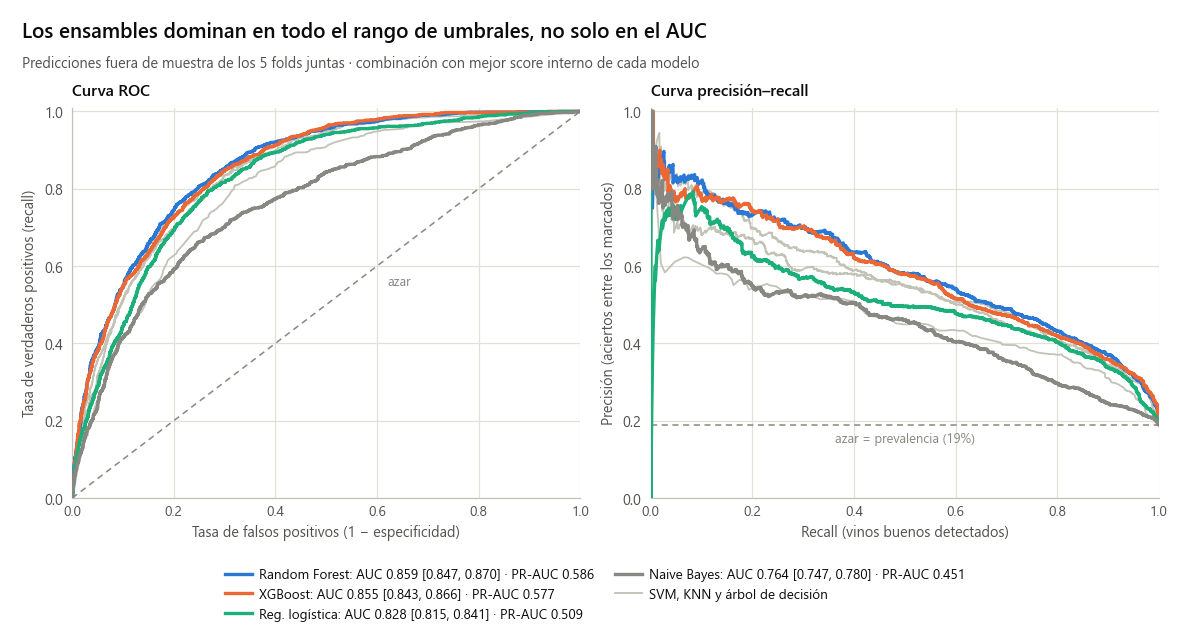

,modelo,balanceo,optimizador,auc_oof,ic95_inf,ic95_sup,pr_auc,tipo_puntaje
0,Random Forest,class_weight,Bayesiano,0.8591,0.8471,0.8702,0.5859,probabilidad
1,XGBoost,class_weight,Bayesiano,0.8552,0.8433,0.8664,0.5765,probabilidad
2,SVM,class_weight,Bayesiano,0.8464,0.8340,0.8580,0.5360,decision
3,KNN,sin_balanceo,Bayesiano,0.8446,0.8322,0.8563,0.5571,probabilidad
4,Regresión Logística (L1/L2),sin_balanceo,Bayesiano,0.8283,0.8148,0.8410,0.5086,probabilidad
5,Decision Tree,class_weight,Bayesiano,0.8011,0.7865,0.8149,0.4536,probabilidad
6,Naive Bayes,class_weight,Grid Search,0.7642,0.7474,0.7802,0.4512,probabilidad


In [3]:
DESTACADOS = {"Random Forest": AZUL, "XGBoost": NARANJA, "Regresión Logística (L1/L2)": AQUA, "Naive Bayes": TINTA_3}
GRIS_SUAVE = EJE
prevalencia = y_clf.mean()

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(10.5, 4.9), layout="constrained")
filas = []
for fila in mejores_clf.to_dict("records"):
    p = predicciones(oof_clf, fila["modelo"], fila["balanceo"], fila["optimizador"])
    auc, inf, sup = auc_con_ic(p["y_true"], p["score"])
    pr_auc = average_precision_score(p["y_true"], p["score"])
    filas.append({"modelo": fila["modelo"], "balanceo": fila["balanceo"], "optimizador": fila["optimizador"],
                  "auc_oof": auc, "ic95_inf": inf, "ic95_sup": sup, "pr_auc": pr_auc, "tipo_puntaje": p["tipo_score"].iloc[0]})
    fpr, tpr, _ = roc_curve(p["y_true"], p["score"])
    precision, recall, _ = precision_recall_curve(p["y_true"], p["score"])
    destacado = fila["modelo"] in DESTACADOS
    estilo = dict(color=DESTACADOS.get(fila["modelo"], GRIS_SUAVE), lw=2.2 if destacado else 1.2,
                  zorder=3 if destacado else 2, solid_capstyle="round")
    ax_roc.plot(fpr, tpr, **estilo)
    ax_pr.plot(recall, precision, **estilo)
tabla_auc = pd.DataFrame(filas).sort_values("auc_oof", ascending=False)

ax_roc.plot([0, 1], [0, 1], color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
ax_roc.text(0.62, 0.55, "azar", color=TINTA_3, fontsize=8.5, rotation=0)
ax_roc.set(xlabel="Tasa de falsos positivos (1 − especificidad)", ylabel="Tasa de verdaderos positivos (recall)",
           xlim=(0, 1), ylim=(0, 1.01), title="Curva ROC")
ax_pr.axhline(prevalencia, color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
ax_pr.text(0.5, prevalencia - 0.045, f"azar = prevalencia ({prevalencia:.0%})", color=TINTA_3, fontsize=8.5, ha="center")
ax_pr.set(xlabel="Recall (vinos buenos detectados)", ylabel="Precisión (aciertos entre los marcados)",
          xlim=(0, 1), ylim=(0, 1.01), title="Curva precisión–recall")
for ax in (ax_roc, ax_pr):
    ax.grid(True)
    ax.set_axisbelow(True)

leyenda = []
for modelo, color in DESTACADOS.items():
    t = tabla_auc[tabla_auc["modelo"] == modelo].iloc[0]
    leyenda.append(Line2D([], [], color=color, lw=2.2,
                          label=f"{corto(modelo)}: AUC {t.auc_oof:.3f} [{t.ic95_inf:.3f}, {t.ic95_sup:.3f}] · PR-AUC {t.pr_auc:.3f}"))
leyenda.append(Line2D([], [], color=GRIS_SUAVE, lw=1.2, label="SVM, KNN y árbol de decisión"))
fig.legend(handles=leyenda, loc="outside lower center", ncols=2, fontsize=8.8)
encabezado(fig, "Los ensambles dominan en todo el rango de umbrales, no solo en el AUC",
           "Predicciones fuera de muestra de los 5 folds juntas · combinación con mejor score interno de cada modelo")
guardar(fig, "fig11_clf_curvas_roc_pr")
plt.show()

display(tabla_auc.round(4))

> **Resultado:** las curvas de Random Forest y XGBoost quedan por encima de las demás en casi todo el recorrido, así que su ventaja no depende del umbral que se elija. Con las predicciones juntas, el AUC de Random Forest es 0.859 (IC 95%: 0.847–0.870) y el de XGBoost 0.855; los intervalos se solapan casi por completo, igual que en el test de Nemenyi. La curva precisión–recall muestra lo difícil de la clase minoritaria: para recuperar el 80% de los vinos buenos, incluso el mejor modelo tiene que aceptar que más de la mitad de los marcados como "buenos" no lo sean (precisión ≈ 0.42).

## 3. Punto de operación: matriz de confusión y umbral

Con un umbral de 0.5 los modelos sin balanceo marcan pocos vinos como buenos. Hay dos maneras de mover ese punto de operación: **balancear** el entrenamiento (SMOTE, ADASYN, `class_weight`), que infla las probabilidades de la clase minoritaria, o **cambiar el umbral** de decisión. Para comparar las dos sin hacer trampa, el umbral se elige **solo con el entrenamiento externo** de cada fold: se generan predicciones internas con 3 folds (`cross_val_predict`), se toma el umbral con mayor F1 y recién entonces se aplica a la prueba externa.

In [4]:
SELECCION_UMBRAL = pd.DataFrame([
    ("Random Forest", "class_weight", "Bayesiano"), ("Random Forest", "sin_balanceo", "Bayesiano"),
    tuple(recomendada_clf[CLAVES]), ("XGBoost", "class_weight", "Bayesiano"), ("XGBoost", "sin_balanceo", "Bayesiano"),
    ("Regresión Logística (L1/L2)", "sin_balanceo", "Bayesiano")], columns=CLAVES)

ruta_umbrales = RUTA_PREDICCIONES / "umbrales_internos.csv"
umbrales = pd.read_csv(ruta_umbrales) if ruta_umbrales.exists() else pd.DataFrame(columns=CLAVES)
if len(SELECCION_UMBRAL.merge(umbrales[CLAVES].drop_duplicates(), on=CLAVES)) < len(SELECCION_UMBRAL):
    umbrales = umbrales_desde_log(log_clf.merge(SELECCION_UMBRAL, on=CLAVES), X, y_clf)
    umbrales.to_csv(ruta_umbrales, index=False)

con_umbral = oof_clf.merge(umbrales[CLAVES + ["fold", "umbral"]], on=CLAVES + ["fold"])
filas = []
for clave, g in con_umbral.groupby(CLAVES, sort=False):
    for regla, pred in [("0.5", g["score"] >= 0.5), ("elegido en entrenamiento", g["score"] >= g["umbral"])]:
        filas.append({**dict(zip(CLAVES, clave)), "umbral": regla,
                      "umbral_medio": 0.5 if regla == "0.5" else g.groupby("fold")["umbral"].first().mean(),
                      "precision": precision_score(g["y_true"], pred), "recall": recall_score(g["y_true"], pred),
                      "f1": f1_score(g["y_true"], pred), "accuracy": accuracy_score(g["y_true"], pred),
                      "marcados_buenos": int(pred.sum())})
tabla09 = pd.DataFrame(filas).sort_values(["modelo", "balanceo", "umbral"]).reset_index(drop=True)
guardar_tabla(tabla09.round(4), "tabla09_clf_umbral_de_operacion")
display(tabla09.round(3))

,modelo,balanceo,optimizador,umbral,umbral_medio,precision,recall,f1,accuracy,marcados_buenos
0,Random Forest,ADASYN,Random Search,0.5,0.500,0.503,0.671,0.575,0.812,1347
1,Random Forest,ADASYN,Random Search,elegido en entrenamiento,0.474,0.479,0.692,0.566,0.799,1457
2,Random Forest,class_weight,Bayesiano,0.5,0.500,0.648,0.385,0.483,0.844,599
3,Random Forest,class_weight,Bayesiano,elegido en entrenamiento,0.320,0.509,0.658,0.574,0.815,1305
4,Random Forest,sin_balanceo,Bayesiano,0.5,0.500,0.667,0.352,0.461,0.844,532
5,Random Forest,sin_balanceo,Bayesiano,elegido en entrenamiento,0.312,0.495,0.652,0.563,0.808,1329
6,Regresión Logística (L1/L2),sin_balanceo,Bayesiano,0.5,0.500,0.568,0.290,0.384,0.823,516
7,Regresión Logística (L1/L2),sin_balanceo,Bayesiano,elegido en entrenamiento,0.252,0.447,0.682,0.540,0.780,1538
8,XGBoost,class_weight,Bayesiano,0.5,0.500,0.515,0.613,0.560,0.817,1203
9,XGBoost,class_weight,Bayesiano,elegido en entrenamiento,0.362,0.462,0.714,0.561,0.788,1558


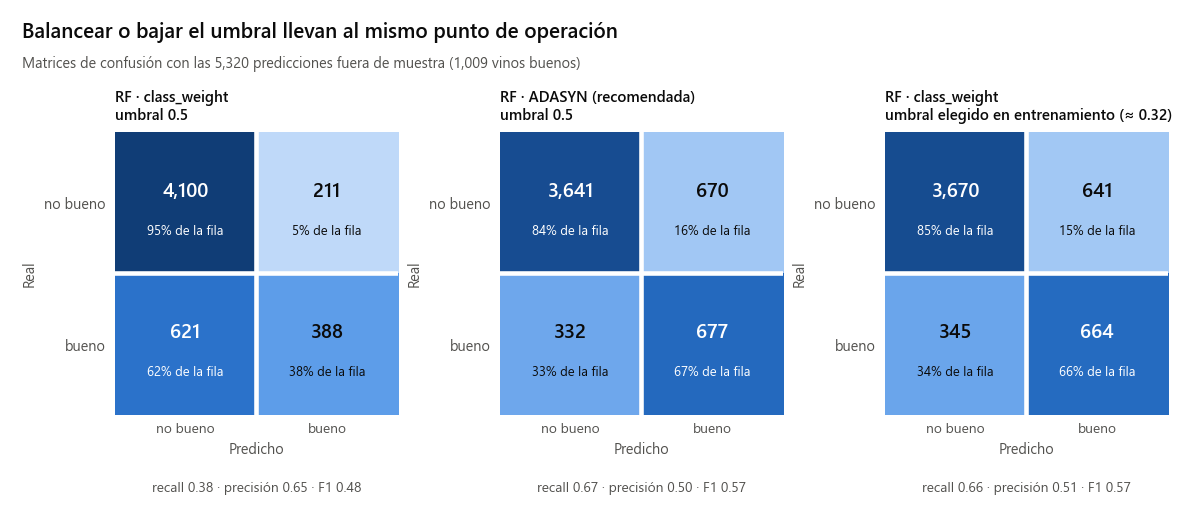

In [5]:
def matriz_confusion(ax, y_true, y_pred, titulo):
    m = confusion_matrix(y_true, y_pred)
    porcentaje = m / m.sum(axis=1, keepdims=True)
    ax.imshow(porcentaje, cmap=CMAP_SECUENCIAL, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            color = FONDO if luminancia(CMAP_SECUENCIAL(porcentaje[i, j])) < 0.18 else TINTA
            ax.text(j, i - 0.08, f"{m[i, j]:,}", ha="center", va="center", fontsize=13, fontweight="semibold", color=color)
            ax.text(j, i + 0.2, f"{porcentaje[i, j]:.0%} de la fila", ha="center", va="center", fontsize=8.5, color=color)
    ax.set_xticks([0, 1], labels=["no bueno", "bueno"])
    ax.set_yticks([0, 1], labels=["no bueno", "bueno"])
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color=FONDO, linewidth=3)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title(titulo, fontsize=9.8, loc="left")


rf_cw = con_umbral[(con_umbral["modelo"] == "Random Forest") & (con_umbral["balanceo"] == "class_weight")].sort_values("idx")
rf_rec = predicciones(oof_clf, *recomendada_clf[CLAVES])
u_medio = rf_cw.groupby("fold")["umbral"].first().mean()
paneles = [
    (rf_cw["y_true"], rf_cw["score"] >= 0.5, "RF · class_weight\numbral 0.5"),
    (rf_rec["y_true"], rf_rec["score"] >= 0.5, f"RF · {recomendada_clf['balanceo']} (recomendada)\numbral 0.5"),
    (rf_cw["y_true"], rf_cw["score"] >= rf_cw["umbral"], f"RF · class_weight\numbral elegido en entrenamiento (≈ {u_medio:.2f})"),
]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9), layout="constrained")
for ax, (yt, yp, titulo) in zip(axes, paneles):
    matriz_confusion(ax, yt, yp, titulo)
    ax.text(0.5, -0.27, f"recall {recall_score(yt, yp):.2f} · precisión {precision_score(yt, yp):.2f} · F1 {f1_score(yt, yp):.2f}",
            transform=ax.transAxes, ha="center", fontsize=9, color=TINTA_2)
encabezado(fig, "Balancear o bajar el umbral llevan al mismo punto de operación",
           f"Matrices de confusión con las {len(rf_cw):,} predicciones fuera de muestra ({int(rf_cw['y_true'].sum()):,} vinos buenos)")
guardar(fig, "fig12_clf_matrices_confusion")
plt.show()

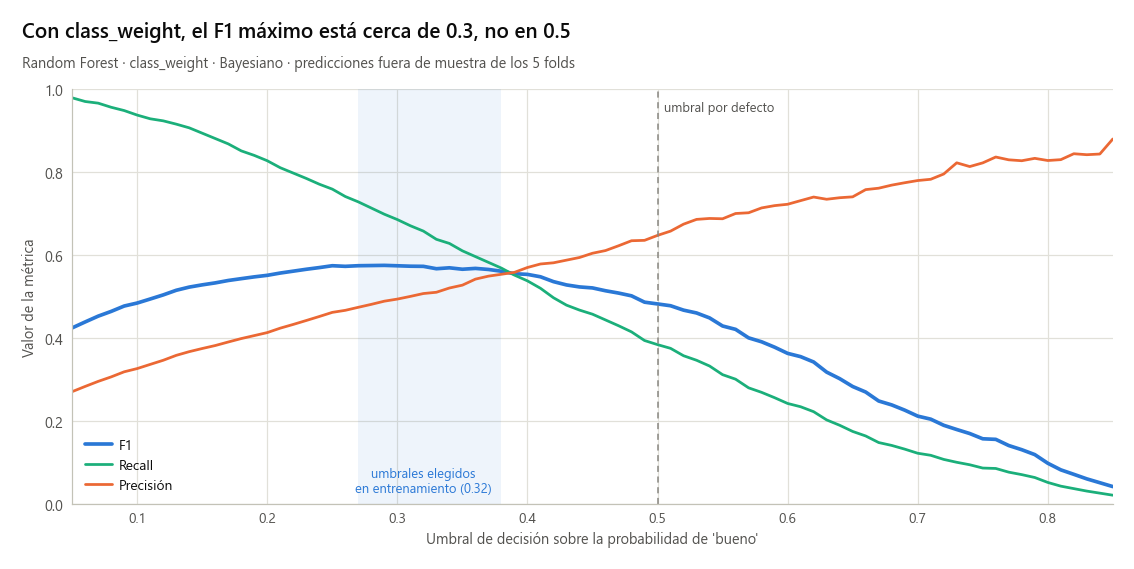

In [6]:
grilla_umbral = np.round(np.arange(0.05, 0.851, 0.01), 2)
curvas = pd.DataFrame({
    "umbral": grilla_umbral,
    "precision": [precision_score(rf_cw["y_true"], rf_cw["score"] >= u, zero_division=0) for u in grilla_umbral],
    "recall": [recall_score(rf_cw["y_true"], rf_cw["score"] >= u) for u in grilla_umbral],
    "f1": [f1_score(rf_cw["y_true"], rf_cw["score"] >= u) for u in grilla_umbral],
})
fig, ax = plt.subplots(figsize=(10, 4.3), layout="constrained")
for columna, color, etiqueta in [("f1", AZUL, "F1"), ("recall", AQUA, "Recall"), ("precision", NARANJA, "Precisión")]:
    ax.plot(curvas["umbral"], curvas[columna], color=color, lw=2.4 if columna == "f1" else 1.8, solid_capstyle="round",
            label=etiqueta)
ax.legend(loc="lower left")
ax.axvline(0.5, color=TINTA_3, lw=1, ls=(0, (4, 3)))
ax.text(0.505, 0.97, "umbral por defecto", color=TINTA_2, fontsize=8.5, va="top")
ax.axvspan(rf_cw.groupby("fold")["umbral"].first().min(), rf_cw.groupby("fold")["umbral"].first().max(),
           color=AZUL, alpha=0.08, lw=0)
ax.text(u_medio, 0.03, f"umbrales elegidos\nen entrenamiento ({u_medio:.2f})", color=AZUL, fontsize=8.5, ha="center")
ax.set(xlim=(0.05, 0.85), ylim=(0, 1), xlabel="Umbral de decisión sobre la probabilidad de 'bueno'", ylabel="Valor de la métrica")
ax.grid(True)
ax.set_axisbelow(True)
encabezado(fig, "Con class_weight, el F1 máximo está cerca de 0.3, no en 0.5",
           "Random Forest · class_weight · Bayesiano · predicciones fuera de muestra de los 5 folds")
guardar(fig, "fig13_clf_metricas_segun_umbral")
plt.show()

> **Resultado:** con el umbral de 0.5, Random Forest con `class_weight` detecta solo el 38% de los vinos buenos (F1 0.48), mientras que la configuración recomendada con ADASYN llega al 67% (F1 0.57). Pero si al mismo Random Forest con `class_weight` se le baja el umbral a ≈ 0.32 —elegido sin tocar la prueba—, recupera el 66% de los vinos buenos con F1 0.57: prácticamente el mismo punto de operación que ADASYN. Lo mismo ocurre sin balanceo (F1 de 0.46 a 0.56) y con la regresión logística (0.38 a 0.54). En estos datos, **balancear y mover el umbral son dos caminos al mismo resultado**; la diferencia está en las probabilidades que quedan, que es lo que se mide a continuación. La figura 13 muestra además que el F1 es bastante plano entre 0.25 y 0.40, así que el umbral exacto no es crítico.

## 4. Calibración de las probabilidades

Un modelo está bien calibrado si, de los vinos a los que asigna 30% de probabilidad de ser buenos, cerca del 30% lo son. Se mide con:

- **Curva de confiabilidad:** probabilidad media predicha frente a la frecuencia observada, en 10 grupos con el mismo número de vinos. La diagonal es la calibración perfecta.
- **ECE** (error de calibración esperado): distancia media entre las dos, ponderada por el tamaño de cada grupo.
- **Brier:** error cuadrático de la probabilidad (mezcla discriminación y calibración); el *Brier skill score* lo compara con predecir siempre el 19% (0 = no mejora, 1 = perfecto).
- **Intercepto y pendiente de calibración:** se ajusta logit(P(bueno)) = a + b·logit(p). Lo ideal es a = 0 y b = 1; a < 0 indica que el modelo sobreestima la probabilidad y b < 1 que sus probabilidades son demasiado extremas.

SVM no entrega probabilidades (se entrenó con `decision_function`), así que solo aparece después de recalibrar. La recalibración usa `CalibratedClassifierCV` con 3 folds **dentro del entrenamiento externo**, por el método de Platt (sigmoide) y por regresión isotónica.

In [7]:
SELECCION_CAL = pd.concat([mejores_clf[CLAVES], recomendada_clf[CLAVES].to_frame().T]).drop_duplicates().reset_index(drop=True)


def oof_recalibrado(metodo):
    ruta = ruta_oof("clasificacion", metodo)
    if ruta.exists():
        guardado = pd.read_csv(ruta)
        if len(SELECCION_CAL.merge(guardado[CLAVES].drop_duplicates(), on=CLAVES)) == len(SELECCION_CAL):
            return guardado
    nuevo, _ = generar_oof("clasificacion", log_clf.merge(SELECCION_CAL, on=CLAVES), X, y_clf,
                           calibracion=metodo, verbose=False)
    nuevo.to_csv(ruta, index=False, compression="gzip")
    return nuevo


versiones_oof = {"original": oof_clf.merge(SELECCION_CAL, on=CLAVES), "Platt (sigmoide)": oof_recalibrado("sigmoid"),
                 "isotónica": oof_recalibrado("isotonic")}
filas = []
for metodo, oof in versiones_oof.items():
    for clave, g in oof.groupby(CLAVES, sort=False):
        if g["tipo_score"].iloc[0] != "probabilidad":
            continue
        g = g.sort_values("idx")
        filas.append({**dict(zip(CLAVES, clave)), "calibracion": metodo, **metricas_probabilisticas(g["y_true"], g["score"]),
                      "f1_umbral_05": f1_score(g["y_true"], g["score"] >= 0.5)})
calibracion = pd.DataFrame(filas)

tabla10 = (calibracion[calibracion["calibracion"] == "original"]
           .drop(columns=["calibracion"]).sort_values("brier").reset_index(drop=True))
guardar_tabla(tabla10.round(4), "tabla10_clf_calibracion")
display(tabla10[["modelo", "balanceo", "auc", "pr_auc", "brier", "brier_skill", "log_loss", "ece", "intercepto_cal",
                 "pendiente_cal", "prob_media"]].round(3))

,modelo,balanceo,auc,pr_auc,brier,brier_skill,log_loss,ece,intercepto_cal,pendiente_cal,prob_media
0,Random Forest,class_weight,0.859,0.586,0.109,0.289,0.346,0.012,-0.009,1.094,0.200
1,KNN,sin_balanceo,0.845,0.557,0.114,0.258,0.364,0.011,-0.081,0.990,0.198
2,Regresión Logística (L1/L2),sin_balanceo,0.828,0.509,0.119,0.226,0.373,0.025,-0.011,0.995,0.190
3,XGBoost,class_weight,0.855,0.577,0.123,0.201,0.376,0.068,-0.711,0.772,0.258
4,Random Forest,ADASYN,0.855,0.567,0.129,0.161,0.397,0.115,-0.865,1.109,0.305
5,Decision Tree,class_weight,0.801,0.454,0.183,-0.194,0.582,0.192,-1.198,0.442,0.377
6,Naive Bayes,class_weight,0.764,0.451,0.285,-0.853,1.019,0.305,-1.539,0.274,0.461


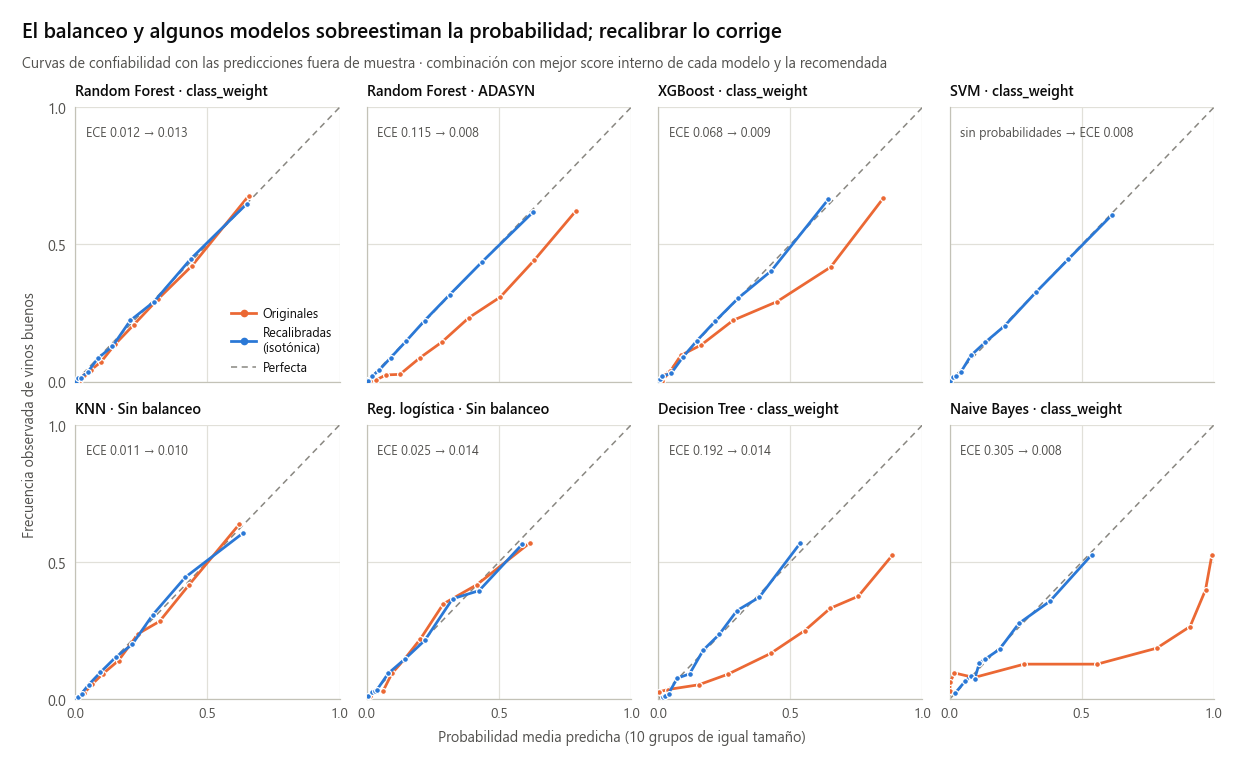

In [8]:
PANELES = [tuple(f) for f in SELECCION_CAL[CLAVES].to_numpy()]
PANELES.sort(key=lambda c: ["Random Forest", "XGBoost", "SVM", "KNN", "Regresión Logística (L1/L2)",
                            "Decision Tree", "Naive Bayes"].index(c[0]) + (0.5 if c[1] in ("ADASYN", "SMOTE") else 0))

fig, axes = plt.subplots(2, 4, figsize=(11, 6.1), layout="constrained", sharex=True, sharey=True)
for ax, clave in zip(axes.flat, PANELES):
    ax.plot([0, 1], [0, 1], color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
    textos = []
    for metodo, color in [("original", NARANJA), ("isotónica", AZUL)]:
        g = versiones_oof[metodo]
        g = g[(g["modelo"] == clave[0]) & (g["balanceo"] == clave[1]) & (g["optimizador"] == clave[2])]
        if g.empty or g["tipo_score"].iloc[0] != "probabilidad":
            textos.append("sin probabilidades" if metodo == "original" else "")
            continue
        curva = curva_confiabilidad(g["y_true"], g["score"], n_bins=10)
        ax.plot(curva["prob_media"], curva["frecuencia"], "-o", color=color, lw=1.8, ms=3.8, mec=FONDO, mew=0.8, zorder=3)
        fila = calibracion[(calibracion["calibracion"] == metodo) & (calibracion["modelo"] == clave[0])
                           & (calibracion["balanceo"] == clave[1]) & (calibracion["optimizador"] == clave[2])].iloc[0]
        textos.append(f"{fila['ece']:.3f}")
    ax.set_title(f"{corto(clave[0])} · {ETIQUETA_BALANCEO[clave[1]]}", fontsize=9.5)
    ece_txt = f"ECE {textos[0]} → {textos[1]}" if textos[0] != "sin probabilidades" else f"sin probabilidades → ECE {textos[1]}"
    ax.text(0.04, 0.93, ece_txt, transform=ax.transAxes, fontsize=8.3, color=TINTA_2, va="top")
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.grid(True)
    ax.set_axisbelow(True)
fig.supxlabel("Probabilidad media predicha (10 grupos de igual tamaño)", fontsize=9.5, color=TINTA_2)
fig.supylabel("Frecuencia observada de vinos buenos", fontsize=9.5, color=TINTA_2)
axes[0, 0].legend(handles=[Line2D([], [], color=NARANJA, marker="o", ms=4, lw=1.8, label="Originales"),
                           Line2D([], [], color=AZUL, marker="o", ms=4, lw=1.8, label="Recalibradas\n(isotónica)"),
                           Line2D([], [], color=TINTA_3, lw=1, ls=(0, (4, 3)), label="Perfecta")],
                  loc="lower right", fontsize=8.3, borderaxespad=0.2)
encabezado(fig, "El balanceo y algunos modelos sobreestiman la probabilidad; recalibrar lo corrige",
           "Curvas de confiabilidad con las predicciones fuera de muestra · combinación con mejor score interno de cada modelo y la recomendada")
guardar(fig, "fig14_clf_curvas_confiabilidad")
plt.show()

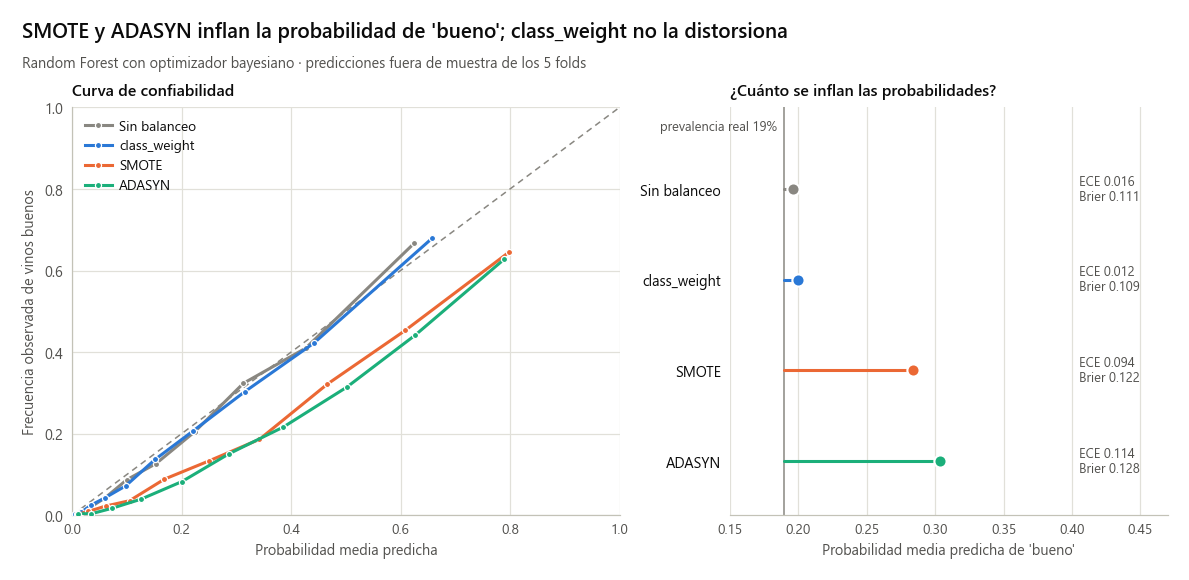

,balanceo,auc,brier,ece,intercepto_cal,pendiente_cal,prob_media
0,sin_balanceo,0.855,0.111,0.016,0.065,1.133,0.196
1,class_weight,0.859,0.109,0.012,-0.009,1.094,0.200
2,SMOTE,0.858,0.122,0.094,-0.744,1.034,0.284
3,ADASYN,0.856,0.128,0.114,-0.851,1.120,0.303


In [9]:
fig, (ax_c, ax_p) = plt.subplots(1, 2, figsize=(10.5, 4.4), width_ratios=[1.25, 1], layout="constrained")
ax_c.plot([0, 1], [0, 1], color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
filas = []
for balanceo in BALANCEOS:
    g = predicciones(oof_clf, "Random Forest", balanceo, "Bayesiano")
    curva = curva_confiabilidad(g["y_true"], g["score"], n_bins=10)
    ax_c.plot(curva["prob_media"], curva["frecuencia"], "-o", color=COLOR_BALANCEO[balanceo], lw=2, ms=4,
              mec=FONDO, mew=0.8, label=ETIQUETA_BALANCEO[balanceo], zorder=3)
    filas.append({"balanceo": balanceo, **metricas_probabilisticas(g["y_true"], g["score"])})
ax_c.set(xlim=(0, 1), ylim=(0, 1), xlabel="Probabilidad media predicha", ylabel="Frecuencia observada de vinos buenos",
         title="Curva de confiabilidad")
ax_c.grid(True)
ax_c.set_axisbelow(True)
ax_c.legend(loc="upper left")

por_balanceo = pd.DataFrame(filas)
y_pos = np.arange(len(BALANCEOS))[::-1]
ax_p.axvline(prevalencia, color=TINTA_3, lw=1)
ax_p.text(prevalencia, len(BALANCEOS) - 0.35, f"prevalencia real {prevalencia:.0%}  ", ha="right", fontsize=8.5, color=TINTA_2)
for yy, fila in zip(y_pos, por_balanceo.itertuples()):
    ax_p.plot([prevalencia, fila.prob_media], [yy, yy], color=COLOR_BALANCEO[fila.balanceo], lw=2, solid_capstyle="round")
    ax_p.plot(fila.prob_media, yy, "o", color=COLOR_BALANCEO[fila.balanceo], ms=8, mec=FONDO, mew=1.4)
    ax_p.text(0.405, yy, f"ECE {fila.ece:.3f}\nBrier {fila.brier:.3f}", va="center", fontsize=8.5, color=TINTA_2)
ax_p.set_yticks(y_pos, labels=[ETIQUETA_BALANCEO[b] for b in BALANCEOS])
ax_p.tick_params(axis="y", labelcolor=TINTA)
ax_p.set(xlim=(0.15, 0.47), ylim=(-0.6, len(BALANCEOS) - 0.1), xlabel="Probabilidad media predicha de 'bueno'",
         title="¿Cuánto se inflan las probabilidades?")
ax_p.grid(axis="x")
ax_p.set_axisbelow(True)
ax_p.spines["left"].set_visible(False)
encabezado(fig, "SMOTE y ADASYN inflan la probabilidad de 'bueno'; class_weight no la distorsiona",
           "Random Forest con optimizador bayesiano · predicciones fuera de muestra de los 5 folds")
guardar(fig, "fig15_clf_calibracion_por_balanceo")
plt.show()
display(por_balanceo[["balanceo", "auc", "brier", "ece", "intercepto_cal", "pendiente_cal", "prob_media"]]
        .round(3))

In [10]:
tabla11 = calibracion.pivot_table(index=["modelo", "balanceo"], columns="calibracion",
                                  values=["auc", "brier", "ece", "log_loss", "f1_umbral_05"])
tabla11 = tabla11.reindex(columns=["original", "Platt (sigmoide)", "isotónica"], level=1)
guardar_tabla(tabla11.round(4).pipe(lambda t: t.set_axis([f"{a}_{b}" for a, b in t.columns], axis=1)).reset_index(),
              "tabla11_clf_recalibracion")
display(tabla11.round(3))

auc                             \
calibracion                              original Platt (sigmoide) isotónica   
modelo                      balanceo                                           
Decision Tree               class_weight    0.801            0.817     0.817   
KNN                         sin_balanceo    0.845            0.846     0.844   
Naive Bayes                 class_weight    0.764            0.760     0.765   
Random Forest               ADASYN          0.855            0.854     0.852   
                            class_weight    0.859            0.859     0.858   
Regresión Logística (L1/L2) sin_balanceo    0.828            0.828     0.826   
SVM                         class_weight      NaN            0.846     0.846   
XGBoost                     class_weight    0.855            0.854     0.854   

                                            brier                             \
calibracion                              original Platt (sigmoide) isotónica   
modelo                      balanceo                                           
Decision Tree               class_weight    0.183            0.123     0.123   
KNN                         sin_balanceo    0.114            0.115     0.114   
Naive Bayes                 class_weight    0.285            0.134     0.130   
Random Forest               ADASYN          0.129            0.113     0.113   
                            class_weight    0.109            0.111     0.110   
Regresión Logística (L1/L2) sin_balanceo    0.119            0.119     0.119   
SVM                         class_weight      NaN            0.114     0.114   
XGBoost                     class_weight    0.123            0.112     0.111   

                                              ece                             \
calibracion                              original Platt (sigmoide) isotónica   
modelo                      balanceo                                           
Decision Tree               class_weight    0.192            0.023     0.014   
KNN                         sin_balanceo    0.011            0.026     0.010   
Naive Bayes                 class_weight    0.305            0.020     0.008   
Random Forest               ADASYN          0.115            0.021     0.008   
                            class_weight    0.012            0.031     0.013   
Regresión Logística (L1/L2) sin_balanceo    0.025            0.024     0.014   
SVM                         class_weight      NaN            0.007     0.008   
XGBoost                     class_weight    0.068            0.031     0.009   

                                         f1_umbral_05                   \
calibracion                                  original Platt (sigmoide)   
modelo                      balanceo                                     
Decision Tree               class_weight        0.505            0.259   
KNN                         sin_balanceo        0.437            0.440   
Naive Bayes                 class_weight        0.444            0.000   
Random Forest               ADASYN              0.575            0.457   
                            class_weight        0.483            0.471   
Regresión Logística (L1/L2) sin_balanceo        0.384            0.382   
SVM                         class_weight          NaN            0.434   
XGBoost                     class_weight        0.560            0.490   

                                                   log_loss                   \
calibracion                              isotónica original Platt (sigmoide)   
modelo                      balanceo                                           
Decision Tree               class_weight     0.301    0.582            0.383   
KNN                         sin_balanceo     0.415    0.364            0.363   
Naive Bayes                 class_weight     0.222    1.019            0.424   
Random Forest               ADASYN           0.437    0.397            0.353   
                            

> **Resultado:** sin recalibrar, Random Forest con `class_weight` (ECE 0.012, pendiente 1.09), KNN (0.011) y la regresión logística (0.025) ya entregan probabilidades confiables. Los demás no: Naive Bayes y el árbol de decisión sobreestiman mucho la probabilidad de "bueno" (ECE 0.31 y 0.19, pendientes 0.27 y 0.44: probabilidades demasiado extremas), y XGBoost con `scale_pos_weight` también la infla (ECE 0.068). En Random Forest, SMOTE y ADASYN suben la probabilidad media de 0.20 a 0.28–0.30 cuando la prevalencia real es 0.19: el modelo aprendió con clases casi balanceadas y cree que los vinos buenos son más comunes de lo que son, por eso su Brier empeora (0.109 → 0.122–0.128) aunque el AUC no cambie.
>
> La recalibración arregla todos los casos: con regresión isotónica el ECE baja a 0.008–0.014 en los ocho modelos (Naive Bayes de 0.305 a 0.008, la configuración recomendada de 0.115 a 0.008) y el Brier de los peor calibrados mejora fuerte (Naive Bayes 0.285 → 0.130), sin perder AUC (cambia menos de 0.003; el árbol incluso sube de 0.801 a 0.817 porque `CalibratedClassifierCV` promedia tres árboles entrenados en distintas partes del entrenamiento). Platt también corrige, con ECE algo mayor (0.007–0.031). El costo es que, con probabilidades realistas, casi ningún vino supera 0.5 y el F1 con ese umbral cae (ADASYN de 0.57 a 0.44): **si se recalibra, hay que elegir el umbral aparte**, igual que se hizo con `class_weight`. Para un sommelier que quiera leer "este vino tiene 70% de probabilidad de ser bueno", lo correcto es un modelo calibrado más un umbral explícito, no el balanceo.

## 5. Regresión: ajuste y análisis de residuos

Se analiza la configuración recomendada de regresión (Random Forest con Grid Search, la de menor RMSE). Primero, cómo se relacionan la nota predicha y la real; después, si los residuos (real − predicho) cumplen los supuestos habituales: normalidad (Jarque–Bera), varianza constante (Breusch–Pagan y White), ausencia de autocorrelación (Ljung–Box, Durbin–Watson) y de dependencia no lineal (BDS).

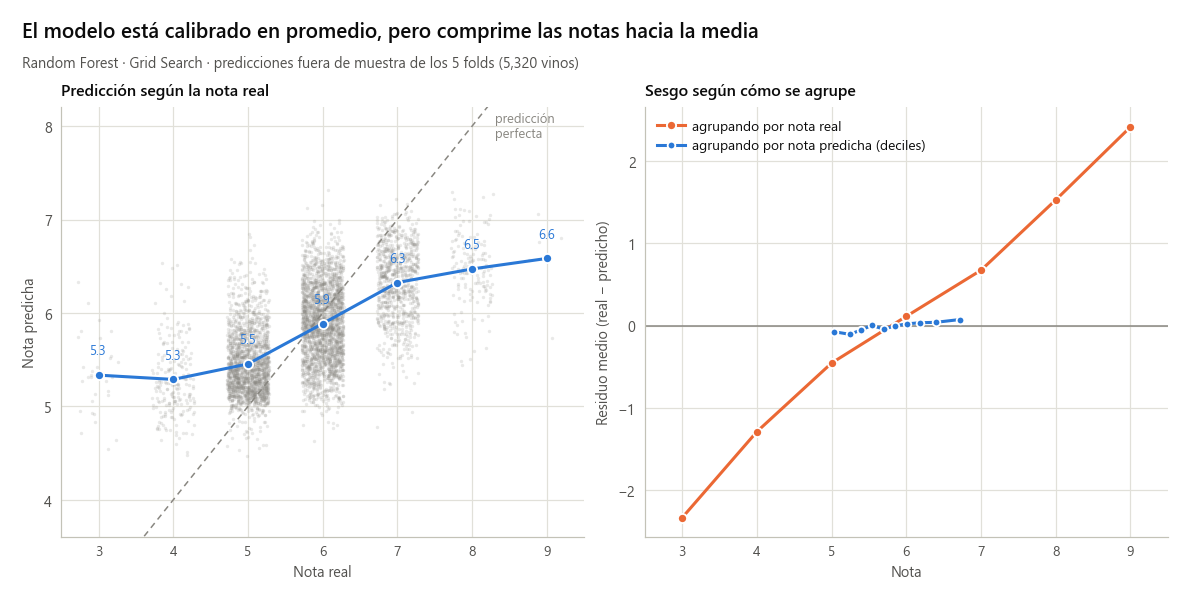

Desviación estándar: real 0.88, predicha 0.51 (cociente 0.58); pendiente de la regresión real ~ predicha: 1.10


In [11]:
rf_reg = predicciones(oof_reg, *recomendada_reg[CLAVES])
real, pred = rf_reg["y_true"].to_numpy(), rf_reg["pred"].to_numpy()
residuo = real - pred
notas = np.arange(3, 10)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(10.5, 4.6), layout="constrained")
rng = np.random.default_rng(7)
ax_a.plot([2.6, 9.4], [2.6, 9.4], color=TINTA_3, lw=1, ls=(0, (4, 3)), zorder=1)
ax_a.text(8.3, 8.0, "predicción\nperfecta", color=TINTA_3, fontsize=8.5, ha="left", va="center")
ax_a.scatter(real + rng.uniform(-0.28, 0.28, len(real)), pred, s=5, color=TINTA_3, alpha=0.18, lw=0, zorder=2)
medias = pd.Series(pred).groupby(real).mean()
ax_a.plot(medias.index, medias.to_numpy(), "-o", color=AZUL, lw=2, ms=6, mec=FONDO, mew=1.2, zorder=4)
for nota, valor in medias.items():
    ax_a.text(nota, valor + 0.22, f"{valor:.1f}", ha="center", fontsize=8.5, color=AZUL)
ax_a.set(xlim=(2.5, 9.5), ylim=(3.6, 8.2), xlabel="Nota real", ylabel="Nota predicha", title="Predicción según la nota real")
ax_a.set_xticks(notas)
ax_a.grid(True)
ax_a.set_axisbelow(True)

sesgo_real = pd.Series(residuo).groupby(real).mean()
grupos = pd.qcut(pred, 10, labels=False)
sesgo_pred = pd.DataFrame({"pred": pred, "e": residuo}).groupby(grupos).mean()
ax_b.axhline(0, color=TINTA_3, lw=1)
ax_b.plot(sesgo_real.index, sesgo_real.to_numpy(), "-o", color=NARANJA, lw=2, ms=6, mec=FONDO, mew=1.2,
          label="agrupando por nota real")
ax_b.plot(sesgo_pred["pred"], sesgo_pred["e"], "-o", color=AZUL, lw=2, ms=5, mec=FONDO, mew=1.2,
          label="agrupando por nota predicha (deciles)")
ax_b.set(xlim=(2.5, 9.5), xlabel="Nota", ylabel="Residuo medio (real − predicho)", title="Sesgo según cómo se agrupe")
ax_b.set_xticks(notas)
ax_b.grid(True)
ax_b.set_axisbelow(True)
ax_b.legend(loc="upper left")
encabezado(fig, "El modelo está calibrado en promedio, pero comprime las notas hacia la media",
           "Random Forest · Grid Search · predicciones fuera de muestra de los 5 folds (5,320 vinos)")
guardar(fig, "fig16_reg_ajuste_y_sesgo")
plt.show()

pendiente = np.polyfit(pred, real, 1)[0]
print(f"Desviación estándar: real {real.std():.2f}, predicha {pred.std():.2f} (cociente {pred.std() / real.std():.2f}); "
      f"pendiente de la regresión real ~ predicha: {pendiente:.2f}")

In [12]:
filas = []
for f in mejores_reg.to_dict("records"):
    g = predicciones(oof_reg, f["modelo"], f["balanceo"], f["optimizador"])
    e = g["y_true"] - g["pred"]
    filas.append({"modelo": f["modelo"], "optimizador": f["optimizador"],
                  **{f"nota_{n}": v for n, v in e.groupby(g["y_true"]).mean().items()},
                  "pendiente_real_vs_pred": np.polyfit(g["pred"], g["y_true"], 1)[0],
                  "de_pred / de_real": g["pred"].std() / g["y_true"].std()})
tabla13 = pd.DataFrame(filas)
tabla13.columns = [c.replace(".0", "") for c in tabla13.columns]
guardar_tabla(tabla13.round(4), "tabla13_reg_sesgo_por_nota")
display(tabla13.round(2))

,modelo,optimizador,nota_3,nota_4,nota_5,nota_6,nota_7,nota_8,nota_9,pendiente_real_vs_pred,de_pred / de_real
0,Random Forest,Bayesiano,-2.35,-1.30,-0.46,0.12,0.68,1.54,2.40,1.11,0.57
1,XGBoost,Bayesiano,-2.27,-1.25,-0.44,0.12,0.68,1.53,2.42,1.05,0.60
2,SVR,Bayesiano,-2.22,-1.23,-0.41,0.14,0.70,1.54,2.41,0.98,0.63
3,KNN,Bayesiano,-2.44,-1.42,-0.50,0.09,0.68,1.52,2.50,1.07,0.57
4,Ridge,Bayesiano,-2.48,-1.44,-0.48,0.13,0.78,1.66,2.55,1.00,0.55
5,Lasso,Bayesiano,-2.48,-1.44,-0.48,0.13,0.78,1.66,2.55,1.00,0.55
6,Decision Tree,Bayesiano,-2.51,-1.42,-0.48,0.13,0.74,1.60,2.44,0.87,0.61


In [13]:
numericas = X[config.COLUMNAS_NUMERICAS]
numericas = (numericas - numericas.mean()) / numericas.std()
rng = np.random.default_rng(config.RANDOM_STATE)
ordenes = {"orden del archivo": np.arange(len(residuo)), "orden aleatorio": rng.permutation(len(residuo)),
           "ordenado por la predicción": np.argsort(pred, kind="stable")}
partes = []
for nombre_orden, orden in ordenes.items():
    t = pruebas_residuos(residuo[orden], numericas.iloc[orden])
    t.insert(0, "orden", nombre_orden)
    partes.append(t)
pruebas = pd.concat(partes, ignore_index=True)
sin_orden = pruebas["prueba"].isin(["Jarque-Bera", "Breusch-Pagan", "White"])
tabla12 = pd.concat([pruebas[sin_orden & (pruebas["orden"] == "orden del archivo")].assign(orden="—"),
                     pruebas[~sin_orden]], ignore_index=True)
tabla12["rechaza_H0_5%"] = np.where(tabla12["p_valor"].isna(), "—", np.where(tabla12["p_valor"] < 0.05, "sí", "no"))
guardar_tabla(tabla12.round(6), "tabla12_reg_pruebas_residuos")
display(tabla12.round({"estadistico": 3}))

,orden,prueba,hipotesis_nula,estadistico,p_valor,detalle,rechaza_H0_5%
0,—,Jarque-Bera,Residuos normales,306.202,3.229617e-67,"asimetría -0.03, curtosis 4.17",sí
1,—,Breusch-Pagan,Varianza constante (lineal en las variables),92.222,6.109177e-15,,sí
2,—,White,Varianza constante (cuadrados y productos cruzados),306.854,3.405609e-29,,sí
3,orden del archivo,Ljung-Box (rezago 10),Sin autocorrelación en el orden de los datos,121.085,3.047777e-21,,sí
4,orden del archivo,Ljung-Box (rezago 20),Sin autocorrelación en el orden de los datos,161.292,4.227654e-24,,sí
5,orden del archivo,Durbin-Watson,Sin autocorrelación de orden 1 (≈ 2),1.841,NaN,,—
6,orden del archivo,BDS (dimensión 2),Residuos i.i.d. (sin dependencia no lineal),5.510,3.581957e-08,,sí
7,orden del archivo,BDS (dimensión 3),Residuos i.i.d. (sin dependencia no lineal),5.563,2.649503e-08,,sí
8,orden aleatorio,Ljung-Box (rezago 10),Sin autocorrelación en el orden de los datos,2.792,9.858971e-01,,no
9,orden aleatorio,Ljung-Box (rezago 20),Sin autocorrelación en el orden de los datos,6.732,9.974750e-01,,no


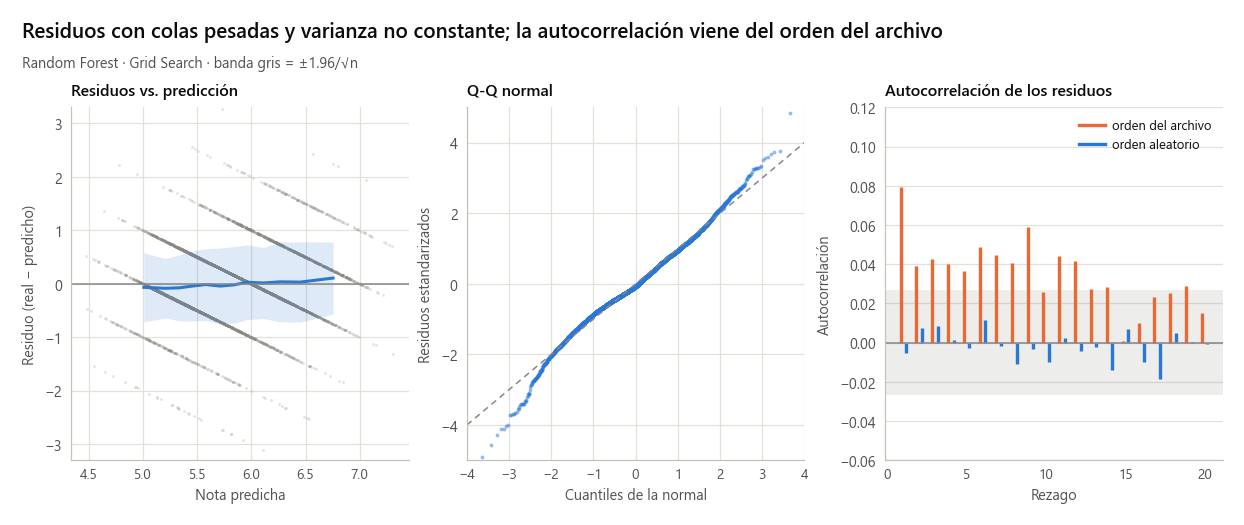

In [14]:
fig, (ax_r, ax_q, ax_acf) = plt.subplots(1, 3, figsize=(11, 3.9), layout="constrained")
ax_r.scatter(pred, residuo, s=4, color=TINTA_3, alpha=0.2, lw=0)
bins = pd.qcut(pred, 12, labels=False)
resumen_bins = pd.DataFrame({"p": pred, "e": residuo}).groupby(bins).agg(p=("p", "mean"), m=("e", "mean"), s=("e", "std"))
ax_r.fill_between(resumen_bins["p"], resumen_bins["m"] - resumen_bins["s"], resumen_bins["m"] + resumen_bins["s"],
                  color=AZUL, alpha=0.15, lw=0)
ax_r.plot(resumen_bins["p"], resumen_bins["m"], color=AZUL, lw=2)
ax_r.axhline(0, color=TINTA_3, lw=1)
ax_r.set(xlabel="Nota predicha", ylabel="Residuo (real − predicho)", title="Residuos vs. predicción", ylim=(-3.3, 3.3))
ax_r.grid(True)
ax_r.set_axisbelow(True)

(teoricos, ordenados), (pend, inter, _) = stats.probplot((residuo - residuo.mean()) / residuo.std(), dist="norm")
ax_q.plot(teoricos, ordenados, "o", ms=2.5, color=AZUL, alpha=0.5, mec="none")
ax_q.plot([-4, 4], [-4, 4], color=TINTA_3, lw=1, ls=(0, (4, 3)))
ax_q.set(xlim=(-4, 4), ylim=(-5, 5), xlabel="Cuantiles de la normal", ylabel="Residuos estandarizados",
         title="Q-Q normal")
ax_q.grid(True)
ax_q.set_axisbelow(True)

rezagos = np.arange(1, 21)
banda = 1.96 / np.sqrt(len(residuo))
ax_acf.axhspan(-banda, banda, color=TINTA_3, alpha=0.15, lw=0)
for nombre_orden, color, desplazamiento in [("orden del archivo", NARANJA, -0.17), ("orden aleatorio", AZUL, 0.17)]:
    valores = acf(residuo[ordenes[nombre_orden]], nlags=20)[1:]
    ax_acf.vlines(rezagos + desplazamiento, 0, valores, color=color, lw=2.2)
ax_acf.axhline(0, color=TINTA_3, lw=1)
ax_acf.set(xlabel="Rezago", ylabel="Autocorrelación", title="Autocorrelación de los residuos", ylim=(-0.06, 0.12))
ax_acf.legend(handles=[Line2D([], [], color=NARANJA, lw=2.2, label="orden del archivo"),
                       Line2D([], [], color=AZUL, lw=2.2, label="orden aleatorio")], loc="upper right", fontsize=8.5)
ax_acf.grid(axis="y")
ax_acf.set_axisbelow(True)
encabezado(fig, "Residuos con colas pesadas y varianza no constante; la autocorrelación viene del orden del archivo",
           "Random Forest · Grid Search · banda gris = ±1.96/√n")
guardar(fig, "fig17_reg_diagnostico_residuos")
plt.show()

> **Resultado:** la figura 16 muestra el patrón más importante de la regresión. Agrupando por **nota predicha**, el residuo medio es casi cero en todo el rango (−0.1 a +0.08): cuando el modelo dice 6.2, la nota real promedio es ≈ 6.2, o sea que el modelo está calibrado. Agrupando por **nota real**, en cambio, el sesgo es enorme en los extremos: a los vinos de nota 3 les predice 5.3 y a los de 9, 6.6. Las predicciones tienen una desviación estándar de 0.51 frente a 0.88 de las notas reales: el modelo comprime todo hacia la media (≈ 5.8). No es un defecto exclusivo del Random Forest: los siete modelos tienen el mismo sesgo por nota (tabla 13), porque con un R² de 0.40 la química no alcanza para reconocer los vinos excepcionales. Para un uso práctico, el modelo sirve para ordenar y para estimar la nota de vinos típicos, no para detectar los extremos.
>
> Las pruebas sobre los residuos (tabla 12):
> - **Normalidad:** Jarque–Bera la rechaza (curtosis 4.2, colas más pesadas que la normal; el Q-Q se separa de la diagonal en los extremos). Es esperable con una variable respuesta entera; Random Forest no supone normalidad, pero intervalos de predicción del tipo ±1.96·σ no serían confiables.
> - **Varianza constante:** Breusch–Pagan y White la rechazan (p < 10⁻⁶): la dispersión del residuo cambia con la nota predicha (d.e. de 0.59 a 0.75 según el tramo).
> - **Autocorrelación y BDS:** en el orden del archivo, Ljung–Box y BDS rechazan la independencia, pero Durbin–Watson es 1.84 (correlación de orden 1 de apenas 0.08). Al desordenar los vinos al azar la autocorrelación desaparece (Ljung–Box p ≈ 0.99, BDS p > 0.2), así que no es una falla del modelo sino del orden de las filas: vinos consecutivos en los archivos originales se parecen entre sí más de lo que la química explica (probablemente lotes o productores parecidos). Ordenando por la predicción, Ljung–Box no rechaza (p = 0.18): no queda una curvatura sistemática sin capturar, y el BDS débil (p ≈ 0.01–0.02) refleja la heterocedasticidad. Como los folds son aleatorios, vinos "hermanos" pueden caer en entrenamiento y prueba, lo que podría hacer algo optimistas las métricas.

## 6. Conclusiones de la evaluación detallada

1. **Los ensambles ganan en todo el recorrido de umbrales.** Las curvas ROC y precisión–recall de Random Forest y XGBoost dominan a las demás; con las predicciones de los 5 folds juntas el AUC de Random Forest es 0.859 [0.847, 0.870].
2. **El balanceo es, en la práctica, un cambio de umbral.** Random Forest con `class_weight` y un umbral elegido solo con el entrenamiento (≈ 0.32) alcanza el mismo recall (0.66) y F1 (0.57) que la configuración recomendada con ADASYN.
3. **Pero el balanceo por sobremuestreo descalibra.** SMOTE y ADASYN inflan la probabilidad media de 0.20 a 0.28–0.30 (ECE 0.09–0.11). Naive Bayes, el árbol y XGBoost con `scale_pos_weight` también quedan mal calibrados. La recalibración isotónica dentro del entrenamiento lleva el ECE de todos a ≈ 0.01 sin costo en AUC.
4. **Recomendación ajustada:** si solo importa clasificar con umbral 0.5, Random Forest + ADASYN sigue siendo una buena opción; si se quieren probabilidades interpretables, es mejor Random Forest con `class_weight` (ya calibrado) y un umbral explícito de ≈ 0.3.
5. **En regresión, el modelo está calibrado pero comprime las notas** (pendiente 1.10, d.e. predicha 0.51 vs 0.88 real): sobreestima los vinos malos y subestima los excelentes, igual que los otros seis modelos. Los residuos no son normales ni homocedásticos, y la autocorrelación que muestran se explica por el orden del archivo.